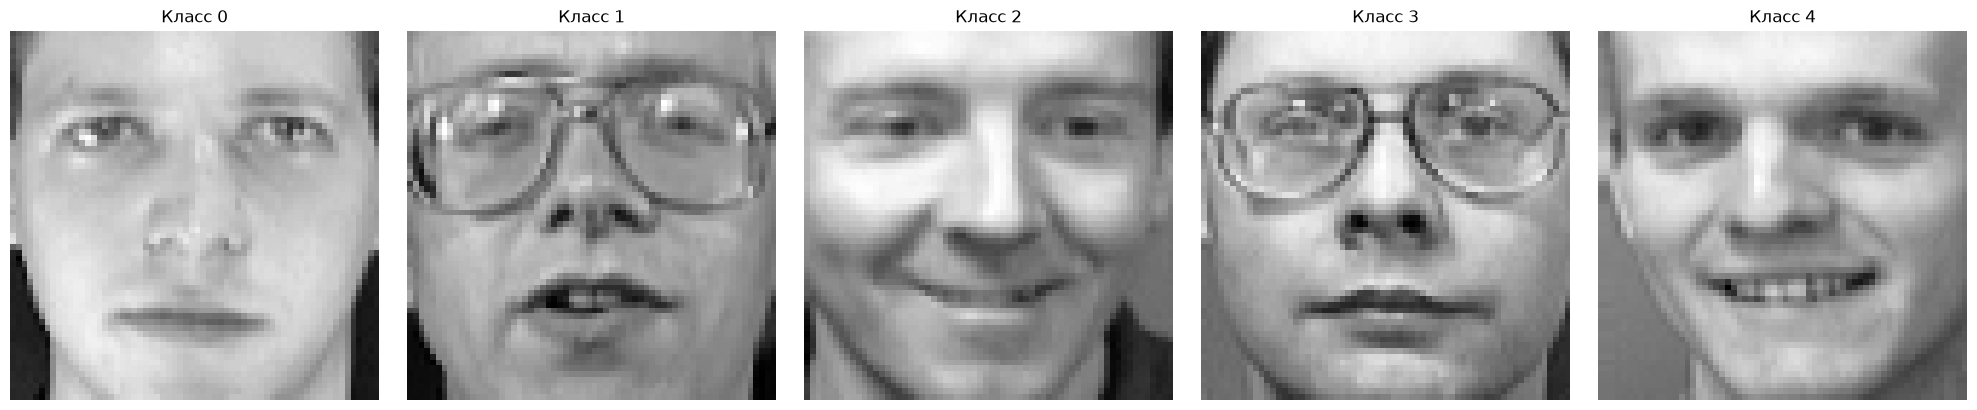

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()
images = faces.images
labels = faces.target

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    image = images[10*i]
    label = labels[10*i]
    axes[i].imshow(image, cmap='gray')
    axes[i].set_title(f'Класс {label}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## Задание 1: Классификация лиц из набора данных Olivetti Faces с помощью алгоритмов градиентного бустинга

In [2]:
from sklearn.model_selection import train_test_split

images /= 255
images = images.reshape(400, -1)

X_train, X_test, y_train, y_test = train_test_split(images, labels, test_size=0.25, stratify=labels, random_state=42)
images.shape

(400, 4096)

In [6]:
import optuna
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def make_model(trial, name):
    if name == "xgb":
        return XGBClassifier(
            n_estimators=trial.suggest_int("n_estimators", 50, 200, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.3, log=True),
            max_depth=trial.suggest_int("max_depth", 3, 6),
            gamma=trial.suggest_float("gamma", 0, 2),
            n_jobs=-1,
            random_state=42,
            verbosity=0,
        )
    if name == "lgbm":
        return LGBMClassifier(
            n_estimators=trial.suggest_int("n_estimators", 50, 200, step=50),
            learning_rate=trial.suggest_float("learning_rate", 0.05, 0.3, log=True),
            num_leaves=trial.suggest_int("num_leaves", 8, 64),
            max_depth=trial.suggest_int("max_depth", 3, 7),
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )

    return GradientBoostingClassifier(
        n_estimators=trial.suggest_int("n_estimators", 50, 150, step=50),
        learning_rate=trial.suggest_float("learning_rate", 0.05, 0.2, log=True),
        max_depth=trial.suggest_int("max_depth", 2, 4),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 20),
        random_state=42,
    )

def tune(name, X, y, n_trials=10):
    def objective(trial):
        model = make_model(trial, name)
        return cross_val_score(
            model, X, y, cv=cv, scoring="accuracy", n_jobs=-1
        ).mean()

    study = optuna.create_study(
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=42)
    )
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    print(name, study.best_value, study.best_params)
    return study

studies = {n: tune(n, X_train, y_train) for n in ["xgb", "lgbm", "sk"]}
studies

[I 2026-10-24 14:53:02,752] A new study created in memory with name: no-name-eff00627-c5fd-4a3b-b619-499c9ef235b8
Best trial: 0. Best value: 0.686667:  10%|█         | 1/10 [00:20<03:02, 20.31s/it]

[I 2026-10-24 14:53:23,059] Trial 0 finished with value: 0.6866666666666666 and parameters: {'n_estimators': 100, 'learning_rate': 0.2746436300285509, 'max_depth': 5, 'gamma': 1.1973169683940732}. Best is trial 0 with value: 0.6866666666666666.


Best trial: 0. Best value: 0.686667:  20%|██        | 2/10 [00:40<02:43, 20.43s/it]

[I 2026-10-24 14:53:43,576] Trial 1 finished with value: 0.68 and parameters: {'n_estimators': 50, 'learning_rate': 0.06612372870684138, 'max_depth': 3, 'gamma': 1.7323522915498704}. Best is trial 0 with value: 0.6866666666666666.


Best trial: 2. Best value: 0.693333:  30%|███       | 3/10 [01:13<03:03, 26.21s/it]

...

Best trial: 6. Best value: 0.773333: 100%|██████████| 10/10 [03:38<00:00, 21.86s/it]
[I 2026-10-24 15:02:01,681] A new study created in memory with name: no-name-d7689f80-6720-4628-a4fd-fa2f7e13ba93


[I 2026-10-24 15:02:01,672] Trial 9 finished with value: 0.7633333333333333 and parameters: {'n_estimators': 100, 'learning_rate': 0.05956260478030898, 'num_leaves': 47, 'max_depth': 5}. Best is trial 6 with value: 0.7733333333333333.
lgbm 0.7733333333333333 {'n_estimators': 100, 'learning_rate': 0.20415295029478484, 'num_leaves': 19, 'max_depth': 5}


  0%|          | 0/10 [03:11<?, ?it/s]


[W 2026-10-24 15:05:12,751] Trial 0 failed with parameters: {'n_estimators': 100, 'learning_rate': 0.18679147494991152, 'max_depth': 4, 'min_samples_leaf': 14} because of the following error: KeyboardInterrupt().
Traceback (most recent call last):
  File "/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/var/folders/sl/c1q8vzl53xl0g5kgw_r8t_bh0000gn/T/ipykernel_57636/4207794013.py", line 42, in objective
    return cross_val_score(
           ~~~~~~~~~~~~~~~^
        model, X, y, cv=cv, scoring="accuracy", n_jobs=-1
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ).mean()
    ^
  File "/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/utils/_param_validation.py", line 218, in wrapper
    return func(*args, **kwargs)
  File "/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", l

KeyboardInterrupt: 


Модель: XGB
Accuracy: 0.7100

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      0.67      0.80         3
           2       0.75      1.00      0.86         3
           3       1.00      0.33      0.50         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      0.50      0.67         2
           7       0.50      0.33      0.40         3
           8       0.40      1.00      0.57         2
           9       0.00      0.00      0.00         2
          10       0.50      0.33      0.40         3
          11       1.00      0.67      0.80         3
          12       0.50      0.50      0.50         2
          13       0.67      1.00      0.80         2
          14       1.00      1.00      1.00         3
          15       0.50      0.50      0.50         2
          16       0.67    

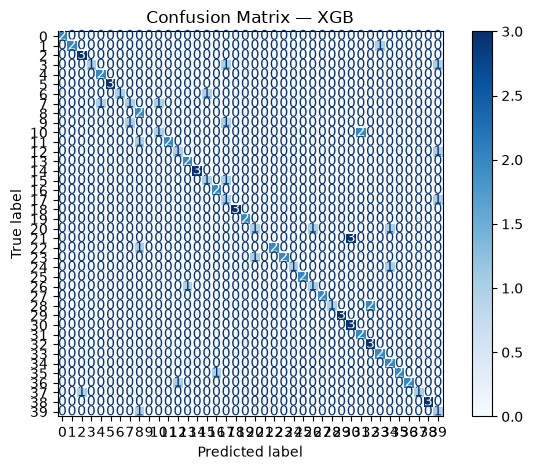


Модель: LGBM
Accuracy: 0.8300

Classification Report:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       0.50      1.00      0.67         2
           5       1.00      0.67      0.80         3
           6       0.50      0.50      0.50         2
           7       0.50      0.33      0.40         3
           8       1.00      1.00      1.00         2
           9       0.00      0.00      0.00         2
          10       1.00      0.33      0.50         3
          11       1.00      1.00      1.00         3
          12       1.00      0.50      0.67         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.50      0.50      0.50         2
          16       0.00   

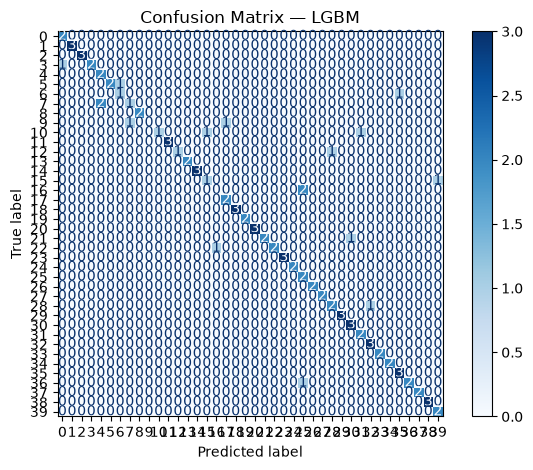


Модель: SK
Accuracy: 0.8000

Classification Report:
              precision    recall  f1-score   support

           0       0.40      1.00      0.57         2
           1       1.00      1.00      1.00         3
           2       0.67      0.67      0.67         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      0.50      0.67         2
           7       0.33      0.33      0.33         3
           8       0.40      1.00      0.57         2
           9       1.00      0.50      0.67         2
          10       0.75      1.00      0.86         3
          11       1.00      0.67      0.80         3
          12       0.00      0.00      0.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.33      0.50      0.40         2
          16       1.00     

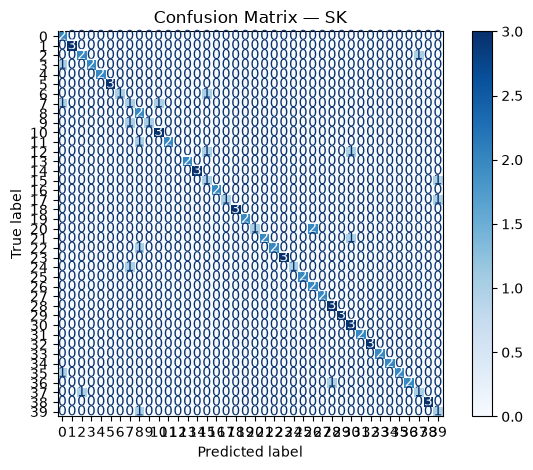

In [15]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_params = {
    "xgb": {
        "n_estimators": 100,
        "learning_rate": 0.1280294493935025,
        "max_depth": 4,
        "gamma": 0.5824582803960838,
    },
    "lgbm": {
        "n_estimators": 100,
        "learning_rate": 0.20415295029478484,
        "num_leaves": 19,
        "max_depth": 5,
    },
    "sk": {
        "n_estimators": 120,
        "learning_rate": 0.1,
        "max_depth": 3,
        "min_samples_leaf": 8,
    }
}

for name, params in best_params.items():
    print(f"\n{'='*50}")
    print(f"Модель: {name.upper()}")
    print('='*50)
    
    if name == "xgb":
        model = XGBClassifier(**params, n_jobs=-1, random_state=42, verbosity=0)
    elif name == "lgbm":
        model = LGBMClassifier(**params, n_jobs=-1, random_state=42, verbose=-1)
    else:
        model = GradientBoostingClassifier(**params, random_state=42)

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
    
    print("Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))
    
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"Confusion Matrix — {name.upper()}")
    plt.tight_layout()
    plt.show()

## Задание 2: Классификация лиц из набора Olivetti Faces с помощью ансамбля классификаторов VotingClassifier

Accuracy: 0.2800

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.50      0.40         2
           1       0.00      0.00      0.00         3
           2       0.00      0.00      0.00         3
           3       0.00      0.00      0.00         3
           4       1.00      0.50      0.67         2
           5       0.00      0.00      0.00         3
           6       0.40      1.00      0.57         2
           7       0.00      0.00      0.00         3
           8       0.25      0.50      0.33         2
           9       0.50      0.50      0.50         2
          10       0.00      0.00      0.00         3
          11       0.00      0.00      0.00         3
          12       0.00      0.00      0.00         2
          13       1.00      1.00      1.00         2
          14       0.00      0.00      0.00         3
          15       0.50      1.00      0.67         2
          16       0.10      0.50      0

/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

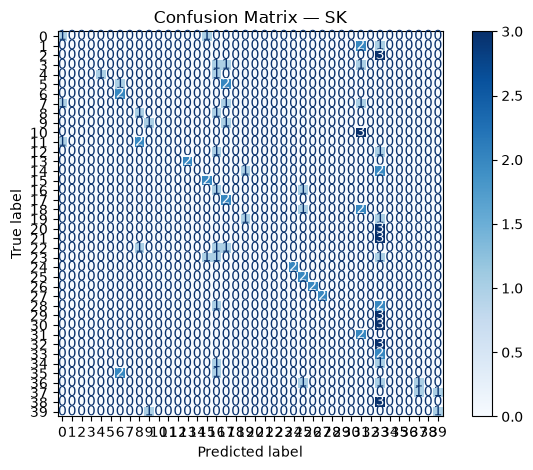

Accuracy: 0.8700

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         2
           1       1.00      1.00      1.00         3
           2       1.00      0.33      0.50         3
           3       1.00      0.67      0.80         3
           4       0.67      1.00      0.80         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         3
          15       0.00      0.00      0.00         2
          16       1.00      0.50      0

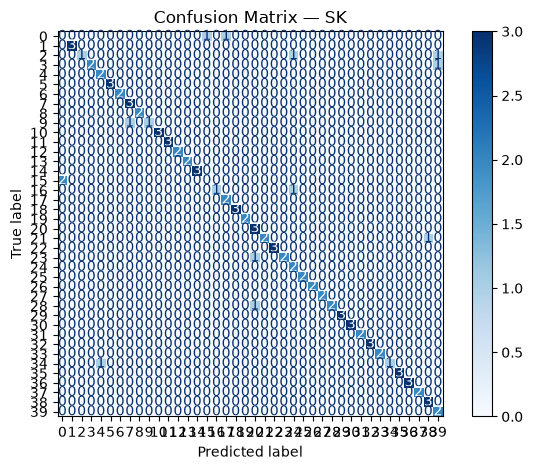

Accuracy: 0.6200

Classification Report:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.33      0.67      0.44         3
           2       0.40      0.67      0.50         3
           3       0.20      0.33      0.25         3
           4       0.40      1.00      0.57         2
           5       1.00      1.00      1.00         3
           6       1.00      0.50      0.67         2
           7       0.00      0.00      0.00         3
           8       0.67      1.00      0.80         2
           9       0.33      0.50      0.40         2
          10       0.75      1.00      0.86         3
          11       1.00      0.67      0.80         3
          12       0.50      0.50      0.50         2
          13       0.00      0.00      0.00         2
          14       1.00      0.67      0.80         3
          15       0.00      0.00      0.00         2
          16       0.50      0.50      0

/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/iaroslav/Desktop/ml_course/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifi

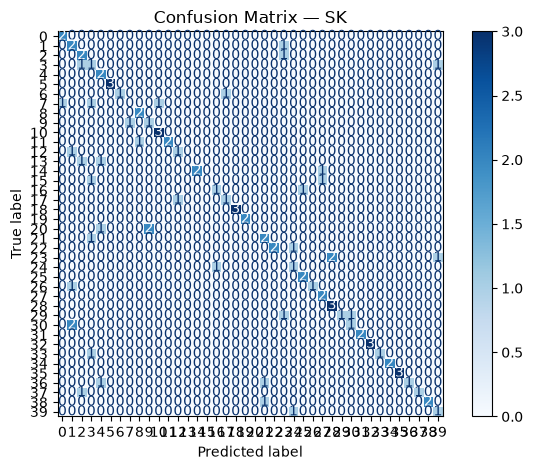

Accuracy: 0.9200

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      0.67      0.80         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       0.67      1.00      0.80         2
          13       1.00      0.50      0.67         2
          14       1.00      1.00      1.00         3
          15       0.50      1.00      0.67         2
          16       1.00      0.50      0

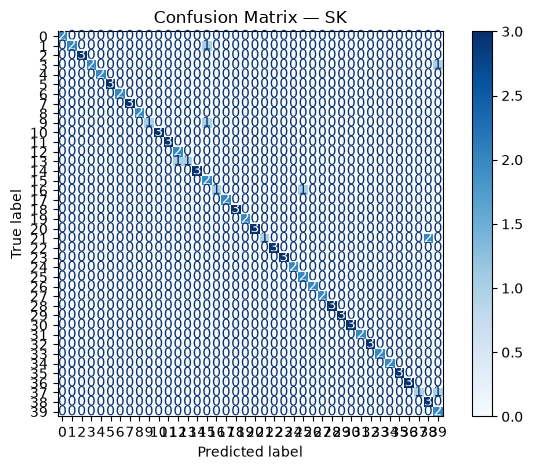

In [16]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

log_reg = LogisticRegression()
knn = KNeighborsClassifier()
tree = DecisionTreeClassifier()
bayes = GaussianNB()

for model in [log_reg, knn, tree, bayes]:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
    plt.title(f"Confusion Matrix — {name.upper()}")
    plt.tight_layout()
    plt.show()

Accuracy: 0.9200

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      0.67      0.80         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       0.75      1.00      0.86         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       0.67      1.00      0.80         2
          13       1.00      0.50      0.67         2
          14       1.00      1.00      1.00         3
          15       0.67      1.00      0.80         2
          16       1.00      0.50      0

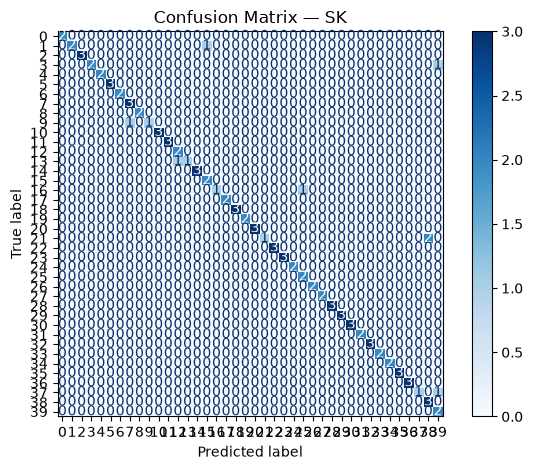

In [17]:
voting = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("knn", KNeighborsClassifier()),
        ("dt", DecisionTreeClassifier()),
        ("nb", GaussianNB())
    ], voting='soft')

voting.fit(X_train, y_train)
y_pred = voting.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title(f"Confusion Matrix — {name.upper()}")
plt.tight_layout()
plt.show()

## Задание 3: Классификация лиц из набора Olivetti Faces с помощью ансамбля классификаторов StackingClassifier

Accuracy: 0.9300

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      0.67      0.80         3
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         3
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         2
          13       1.00      0.50      0.67         2
          14       1.00      1.00      1.00         3
          15       0.67      1.00      0.80         2
          16       1.00      0.50      0

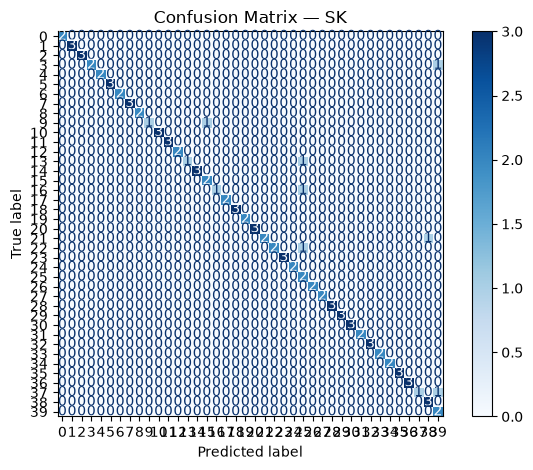

In [18]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(
    estimators=[
        ("lr", LogisticRegression(max_iter=1000)),
        ("knn", KNeighborsClassifier()),
        ("dt", DecisionTreeClassifier()),
        ("nb", GaussianNB())
    ], final_estimator=LogisticRegression())

stacking.fit(X_train, y_train)
y_pred = stacking.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title(f"Confusion Matrix — {name.upper()}")
plt.tight_layout()
plt.show()

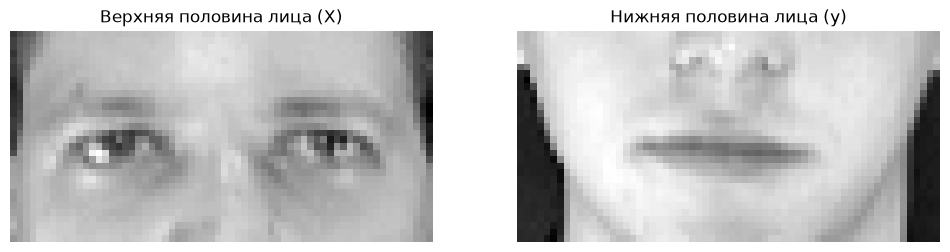

LightGBM          R2 = 0.5663 | время обучения = 11.2 c
XGBoost           R2 = 0.5113 | время обучения = 64.5 c


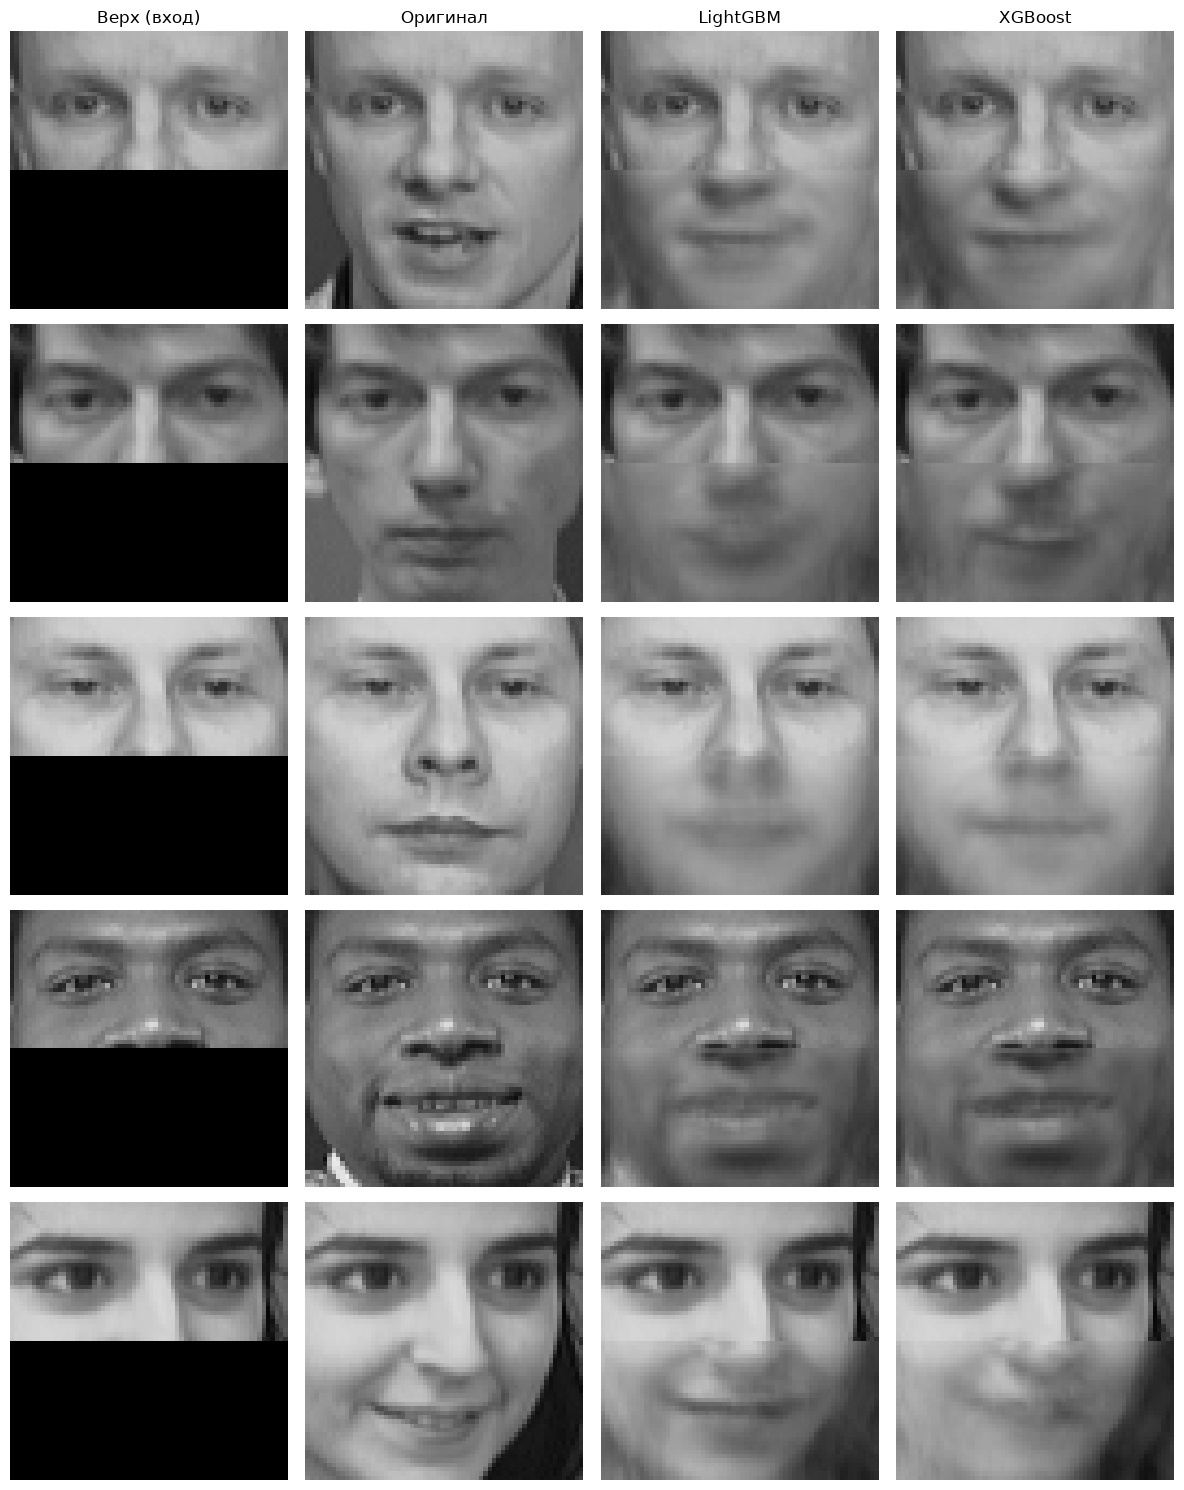

In [21]:
import time
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()
images = faces.images  # Изображения размером 64x64
n_samples = images.shape[0]
upper_half = images[:, :32, :]  # Верхняя половина (первые 32 строки)
lower_half = images[:, 32:, :]  # Нижняя половина (последние 32 строки)

X = upper_half.reshape((n_samples, -1))
y = lower_half.reshape((n_samples, -1))

sample_index = 0  # Измените значение для выбора другого изображения

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2048px -> 50
pca = PCA(n_components=50, random_state=42).fit(y_train)
z_train = pca.transform(y_train)

models = {
    "LightGBM": MultiOutputRegressor(LGBMRegressor(n_estimators=100, colsample_bytree=0.3, verbose=-1, n_jobs=1), n_jobs=-1),
    "XGBoost": MultiOutputRegressor(XGBRegressor(n_estimators=100, colsample_bytree=0.3, n_jobs=1), n_jobs=-1)
}

preds = {}
for name, model in models.items():
    t = time.perf_counter()
    model.fit(X_train, z_train)
    fit_time = time.perf_counter() - t
    preds[name] = pca.inverse_transform(model.predict(X_test))
    print(f"{name:17s} R2 = {r2_score(y_test, preds[name]):.4f} | время обучения = {fit_time:.1f} c")

n_show = 5
titles = ["Верх (вход)", "Оригинал"] + list(models)
fig, axes = plt.subplots(n_show, len(titles), figsize=(3 * len(titles), 3 * n_show))
for i in range(n_show):
    up = X_test[i].reshape(32, 64)
    imgs = [np.vstack([up, np.zeros((32, 64))]),
            np.vstack([up, y_test[i].reshape(32, 64)])]
    imgs += [np.vstack([up, preds[n][i].reshape(32, 64)]) for n in models]
    for j, img in enumerate(imgs):
        axes[i, j].imshow(img, cmap="gray", vmin=0, vmax=1)
        axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(titles[j])
plt.tight_layout()
plt.show()
